# Registros · Fechas

Un registro `Fecha` (día, mes, año) y funciones propias para validarla, compararla, sumarle días o calcular días transcurridos. Los resultados se comprueban contra el módulo `datetime`.

## 1. Fecha larga y fecha válida

Definir `Fecha`, `fecha_larga` (11/9/2001 → *11 de septiembre de 2001*) y `fecha_valida`, que tenga en cuenta los días de cada mes y los años bisiestos.

In [1]:
from dataclasses import dataclass
from datetime import date, timedelta

MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

@dataclass(frozen=True, order=True)
class Fecha:
    anyo: int
    mes: int
    dia: int

def bisiesto(anyo):
    return anyo % 4 == 0 and (anyo % 100 != 0 or anyo % 400 == 0)

def dias_mes(mes, anyo):
    return [31, 29 if bisiesto(anyo) else 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31][mes - 1]

def fecha_larga(f):
    return f"{f.dia} de {MESES[f.mes - 1]} de {f.anyo}"

def fecha_valida(f):
    return 1 <= f.mes <= 12 and 1 <= f.dia <= dias_mes(f.mes, f.anyo)

print(fecha_larga(Fecha(2001, 9, 11)), fecha_valida(Fecha(2000, 4, 31)), fecha_valida(Fecha(2000, 2, 29)), fecha_valida(Fecha(1900, 2, 29)))

11 de septiembre de 2001 False True False


## 2. Leer fechas válidas y ordenarlas

`lee_fecha` debe aceptar solo fechas válidas. Leer una lista de fechas y mostrarlas de la más antigua a la más reciente; comprobar si dos fechas son iguales.

In [2]:
def lee_fecha():
    while True:
        d, m, a = map(int, input("Fecha (d/m/a): ").split("/"))
        f = Fecha(a, m, d)
        if fecha_valida(f):
            return f
        print("Fecha no válida")

def iguales(a, b):
    return a == b

fechas = [lee_fecha() for _ in range(3)]
print([f"{f.dia}/{f.mes}/{f.anyo}" for f in sorted(fechas)], iguales(fechas[0], Fecha(2000, 4, 30)))

Fecha (d/m/a): 31/4/2000
Fecha no válida
Fecha (d/m/a): 30/4/2000
Fecha (d/m/a): 1/1/1999
Fecha (d/m/a): 15/8/2010
['1/1/1999', '30/4/2000', '15/8/2010'] True


## 3. Añadir un día

`anyade_un_dia` debe pasar de 7/6/2001 a 8/6/2001, cuidando el último día del mes, del año y febrero en años bisiestos.

In [3]:
def anyade_un_dia(f):
    if f.dia < dias_mes(f.mes, f.anyo):
        return Fecha(f.anyo, f.mes, f.dia + 1)
    if f.mes < 12:
        return Fecha(f.anyo, f.mes + 1, 1)
    return Fecha(f.anyo + 1, 1, 1)

d = date(1999, 1, 1)
f = Fecha(1999, 1, 1)
for _ in range(3000):
    d, f = d + timedelta(days=1), anyade_un_dia(f)
    assert (f.anyo, f.mes, f.dia) == (d.year, d.month, d.day)
print(anyade_un_dia(Fecha(2001, 6, 7)), anyade_un_dia(Fecha(2004, 2, 28)), anyade_un_dia(Fecha(2001, 12, 31)))

Fecha(anyo=2001, mes=6, dia=8) Fecha(anyo=2004, mes=2, dia=29) Fecha(anyo=2002, mes=1, dia=1)


## 4. Días transcurridos y día de la semana

Calcular los días entre dos fechas (sin la reforma gregoriana) y el día de la semana de cualquier fecha sabiendo que el 1/1/2001 fue lunes.

In [4]:
def dias_desde_origen(f):
    dias = sum(366 if bisiesto(a) else 365 for a in range(1, f.anyo))
    dias += sum(dias_mes(m, f.anyo) for m in range(1, f.mes))
    return dias + f.dia

def dias_transcurridos(a, b):
    return dias_desde_origen(a) - dias_desde_origen(b)

def dia_semana(f):
    dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
    return dias[dias_transcurridos(f, Fecha(2001, 1, 1)) % 7]

print(dias_transcurridos(Fecha(2002, 1, 2), Fecha(2002, 1, 1)))
print(dias_transcurridos(Fecha(2026, 11, 6), Fecha(1970, 1, 1)), (date(2026, 11, 6) - date(1970, 1, 1)).days)
print(dia_semana(Fecha(2026, 11, 6)), dia_semana(Fecha(1969, 7, 20)))

1
20763 20763
viernes domingo


## 5. Reforma gregoriana

En España, tras el jueves 4 de octubre de 1582 se pasó al viernes 15 de octubre: esos 10 días no existieron. Tenerlo en cuenta al contar días entre fechas a ambos lados de la reforma.

In [5]:
REFORMA = Fecha(1582, 10, 15)

def dias_transcurridos_historicos(a, b):
    # el calendario juliano antiguo no tiene la excepción de los siglos
    dias = dias_transcurridos(a, b)
    if b < REFORMA <= a:
        dias -= 10
    elif a < REFORMA <= b:
        dias += 10
    return dias

print(dias_transcurridos_historicos(Fecha(1582, 10, 15), Fecha(1582, 10, 4)))

1


## 6. Biorritmos

Los ciclos físico (23 días), emocional (28) e intelectual (33) se calculan como $\sin(2\pi d / T)$ con $d$ los días vividos (es una superstición popular, no ciencia). Pedir la fecha de nacimiento y la de consulta, mostrar los tres valores y dibujar un mes.

Fecha (d/m/a): 20/7/1990
Fecha (d/m/a): 6/11/2026
físico       +0.40
emocional    +0.00
intelectual  -1.00


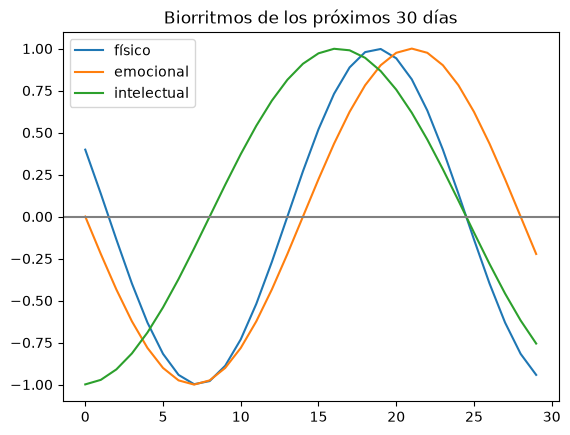

In [6]:
from math import pi, sin
import matplotlib.pyplot as plt

CICLOS = {"físico": 23, "emocional": 28, "intelectual": 33}

nacimiento = lee_fecha()
hoy = lee_fecha()
dias = dias_transcurridos(hoy, nacimiento)
for ciclo, periodo in CICLOS.items():
    print(f"{ciclo:12} {sin(2 * pi * dias / periodo):+.2f}")
for ciclo, periodo in CICLOS.items():
    plt.plot(range(30), [sin(2 * pi * (dias + k) / periodo) for k in range(30)], label=ciclo)
plt.axhline(0, color="grey")
plt.legend()
plt.title("Biorritmos de los próximos 30 días")
plt.show()

## 7. Fecha con hora

Registro `FechaConHora` con funciones para leerla, mostrarla como `19:30 11/9/2001` y como `7:30 pm 11/9/2001`, decidir si una ocurrió antes que otra y calcular los minutos entre dos.

In [7]:
@dataclass(frozen=True, order=True)
class FechaConHora:
    fecha: Fecha
    hora: int
    minutos: int

def lee_fecha_con_hora():
    texto_fecha, texto_hora = input("Fecha y hora (d/m/a hh:mm): ").split()
    d, m, a = map(int, texto_fecha.split("/"))
    h, mi = map(int, texto_hora.split(":"))
    return FechaConHora(Fecha(a, m, d), h, mi)

def formato_24(f):
    return f"{f.hora}:{f.minutos:02d} {f.fecha.dia}/{f.fecha.mes}/{f.fecha.anyo}"

def formato_12(f):
    sufijo = "am" if f.hora < 12 else "pm"
    return f"{(f.hora - 1) % 12 + 1}:{f.minutos:02d} {sufijo} {f.fecha.dia}/{f.fecha.mes}/{f.fecha.anyo}"

def anterior(a, b):
    return a < b

def minutos_entre(a, b):
    return dias_transcurridos(b.fecha, a.fecha) * 1440 + (b.hora * 60 + b.minutos) - (a.hora * 60 + a.minutos)

f = lee_fecha_con_hora()
manana = FechaConHora(Fecha(2001, 9, 11), 7, 30)
print(formato_24(f), "|", formato_12(f), "|", formato_12(manana), anterior(manana, f), minutos_entre(manana, f))

Fecha y hora (d/m/a hh:mm): 11/9/2001 19:30
19:30 11/9/2001 | 7:30 pm 11/9/2001 | 7:30 am 11/9/2001 True 720


## 8. Edad de una persona

Dada una persona con fecha de nacimiento y la fecha de hoy, devolver su edad en años.

In [8]:
def edad(nacimiento, hoy):
    return hoy.anyo - nacimiento.anyo - ((hoy.mes, hoy.dia) < (nacimiento.mes, nacimiento.dia))

print(edad(Fecha(1990, 11, 7), Fecha(2026, 11, 6)), edad(Fecha(1990, 11, 6), Fecha(2026, 11, 6)))

35 36


## 9. Periodos

Registro `Periodo` con dos fechas (inicio ≤ fin): mostrarlo como `d/m/a-d/m/a`, contar sus días (ambos extremos incluidos), saber si contiene una fecha y si dos periodos se solapan.

In [9]:
@dataclass(frozen=True)
class Periodo:
    inicio: Fecha
    fin: Fecha

def breve(f):
    return f"{f.dia}/{f.mes}/{f.anyo}"

def muestra_periodo(p):
    print(f"{breve(p.inicio)}-{breve(p.fin)}")

def dias_periodo(p):
    return dias_transcurridos(p.fin, p.inicio) + 1

def contiene(p, f):
    return p.inicio <= f <= p.fin

def se_solapan(a, b):
    return a.inicio <= b.fin and b.inicio <= a.fin

verano = Periodo(Fecha(2026, 6, 21), Fecha(2026, 9, 22))
agosto = Periodo(Fecha(2026, 8, 1), Fecha(2026, 8, 31))
muestra_periodo(verano)
print(dias_periodo(verano), contiene(verano, Fecha(2026, 7, 4)), se_solapan(verano, agosto), se_solapan(agosto, Periodo(Fecha(2026, 10, 1), Fecha(2026, 10, 2))))

21/6/2026-22/9/2026
94 True True False
